# 02 — Concorrência e preço

**A pergunta:** em mercados com menos companhias, a passagem aérea é mais
cara? Este notebook faz a comparação crua, **sem controle nenhum, de
propósito**: é o que um olhar apressado veria, e o ponto de partida do
notebook 03, que compara mercados de distância parecida.

Faz parte da [etapa 6](https://github.com/ivadivad/voos-em-numeros#etapas) do projeto. Os dados vêm de
`dados/marts/mercado_mes.parquet`, que o `construir.py` monta a partir da
coleta de 13/10/2026: um registro por mercado, mês e grupo econômico, com
os passageiros de voo regular, a participação de cada grupo no mercado e
as somas da tarifa. O que vale daqui em diante:

- **Mercado** é o par de cidades, sem direção: São Paulo–Rio junta
  Congonhas, Guarulhos e Viracopos com Santos Dumont e Galeão, como explica
  o README.
- **Concorrente** é o grupo econômico com pelo menos 5% dos passageiros
  pagos de voo regular do mercado no mês. O limite de 10% e a conta com o
  fretamento entram como sensibilidade, na seção 4.
- **Tarifa por km** é a receita dividida pelos assentos-km, as duas
  somadas, com a distância em linha reta do mercado: o yield que o
  notebook 01 conferiu com a ANAC.
- **A tarifa é de quem vendeu, no mês da venda; o passageiro, de quem
  operou, no mês do voo.** Juntar os dois no mesmo mercado e mês é um
  retrato da estrutura do mercado, que muda devagar, e não o preço pago por
  aqueles passageiros.

In [1]:
import pandas as pd

URL = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/mercado_mes.parquet"
mart = pd.read_parquet(URL)
mart["mes"] = pd.to_datetime(mart["mes"])
mart["ano"] = mart["mes"].dt.year
mercado_meses = mart[["mes", "mercado"]].drop_duplicates()
print(f"{len(mart)} registros, {len(mercado_meses)} mercado-meses, {mart['mercado'].nunique()} mercados, "
      f"{mart['mes'].nunique()} meses ({mart['mes'].min():%m/%Y} a {mart['mes'].max():%m/%Y})")

75147 registros, 30886 mercado-meses, 1089 mercados, 92 meses (01/2019 a 08/2026)


## 1. O que a comparação cobre

A participação de cada grupo vem dos passageiros de voo direto, da base
estatística. Nos mercados só de conexão, em que todo passageiro troca de
voo no caminho, ela não existe, e esses mercados ficam fora do mart. O mart
de validação, que tem todas as tarifas, mostra quanto isso pesa:

In [2]:
VALIDACAO = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/validacao.parquet"
validacao = pd.read_parquet(VALIDACAO)
no_mart, total = mart["assentos_vendidos"].sum(), validacao["assentos_vendidos"].sum()
print(f"assentos vendidos: {no_mart} no mart, de {total} ({no_mart / total:.1%})")

assentos vendidos: 184799396 no mart, de 225811044 (81.8%)


**A comparação cobre 81,8% dos assentos vendidos.** O resto é de mercados
só de conexão, e a pergunta sobre concorrência, medida pelo passageiro de
voo direto, não chega neles.

## 2. Quantos concorrentes tem cada mercado

O mart traz o número de concorrentes de cada mercado no mês. Antes de usar,
a conta é refeita aqui com os mesmos 5%, pra garantir que o notebook e o
SQL falam do mesmo limite:

In [3]:
CLASSES = ["1", "2", "3 ou mais"]


def contar(participacao, limite):
    """Grupos com pelo menos `limite` da participacao, em cada mercado e mes."""
    return (participacao >= limite).groupby([mart["mes"], mart["mercado"]]).sum()


def classe(concorrentes):
    """1, 2 ou 3 ou mais concorrentes."""
    return concorrentes.clip(upper=3).map(dict(zip([1, 2, 3], CLASSES)))


por_mercado = mart.groupby(["mes", "mercado"]).agg(concorrentes=("concorrentes", "first"),
                                                   passageiros=("passageiros_pagos", "sum"))
recontados = contar(mart["participacao"], 0.05)
print("concorrentes recontados com 5%, iguais aos do mart:", (recontados == por_mercado["concorrentes"]).all())

por_mercado["classe"] = classe(por_mercado["concorrentes"])
tamanho = por_mercado.groupby("classe").agg(mercado_meses=("passageiros", "size"), passageiros=("passageiros", "sum"))
tamanho["% dos mercado-meses"] = tamanho["mercado_meses"] / tamanho["mercado_meses"].sum() * 100
tamanho["% dos passageiros"] = tamanho["passageiros"] / tamanho["passageiros"].sum() * 100
print(tamanho.round(1).to_string())

concorrentes recontados com 5%, iguais aos do mart: True
           mercado_meses  passageiros  % dos mercado-meses  % dos passageiros
classe                                                                       
1                  21075     76749569                 68.2               12.4
2                   5716    120565309                 18.5               19.4
3 ou mais           4095    423788848                 13.3               68.2


**A conta bate com a do mart, e o mercado de um concorrente só é o mais
comum, mas leva pouca gente.** São 21.075 dos 30.886 mercado-meses (68,2%),
com 12,4% dos passageiros. Os de três ou mais concorrentes são 13,3% dos
mercado-meses e levam 68,2% dos passageiros.

## 3. A tarifa por número de concorrentes

Ano a ano, pra não misturar a inflação de anos diferentes, e pelo ano da
venda. As três medidas saem da razão entre as somas de cada grupo de
mercados, ponderadas pelos assentos vendidos, como a ANAC calcula a tarifa
média: a tarifa por trecho, a tarifa por km e a distância média. Os
mercados sem distância ficam fora das três medidas, e a célula conta
quantos são.

In [4]:
# mercado sem distancia fica fora das tres medidas
sem_km = mart[mart["assentos_km"].isna()]
print(f"sem distância: {len(sem_km[['mes', 'mercado']].drop_duplicates())} mercado-meses, "
      f"{sem_km['assentos_vendidos'].sum()} assentos vendidos\n")
com_km = mart[mart["assentos_km"].notna()].copy()
com_km["classe"] = classe(com_km["concorrentes"])


def por_classe(registros, coluna="classe"):
    """Tarifa por trecho, tarifa por km e distancia media, por ano e classe,
    todas da razao entre as somas."""
    s = registros.groupby(["ano", coluna])[["receita", "assentos_vendidos", "assentos_km"]].sum()
    return pd.DataFrame({
        "tarifa_trecho": s["receita"] / s["assentos_vendidos"],
        "tarifa_km": s["receita"] / s["assentos_km"],
        "distancia": s["assentos_km"] / s["assentos_vendidos"],
    })


anual = por_classe(com_km)
for medida, titulo, casas in [("tarifa_trecho", "tarifa por trecho (R$)", 0), ("tarifa_km", "tarifa por km (R$)", 3),
                              ("distancia", "distância média (km)", 0)]:
    print(titulo)
    print(anual[medida].unstack().round(casas).to_string(), "\n")

trecho, km = anual["tarifa_trecho"].unstack(), anual["tarifa_km"].unstack()
print("anos com a tarifa por trecho caindo de 1 pra 2 e de 2 pra 3 ou mais:",
      ((trecho["1"] > trecho["2"]) & (trecho["2"] > trecho["3 ou mais"])).sum(), "de", len(trecho))
print("anos com a tarifa por km de 1 acima da de 3 ou mais:", (km["1"] > km["3 ou mais"]).sum(), "de", len(km))
print("anos com a tarifa por km de 2 entre a de 1 e a de 3 ou mais:",
      ((km["2"] < km["1"]) & (km["2"] > km["3 ou mais"])).sum(), "de", len(km))
distancia = anual["distancia"].unstack()
print("anos com a distância média de 1 acima da de 3 ou mais:",
      (distancia["1"] > distancia["3 ou mais"]).sum(), "de", len(distancia))

sem distância: 3 mercado-meses, 580 assentos vendidos

tarifa por trecho (R$)
classe      1      2  3 ou mais
ano                            
2019    461.0  413.0      351.0
2020    379.0  358.0      313.0
2021    478.0  435.0      428.0
2022    647.0  576.0      568.0
2023    681.0  652.0      537.0
2024    677.0  641.0      544.0
2025    719.0  621.0      556.0
2026    742.0  633.0      587.0 

tarifa por km (R$)
classe      1      2  3 ou mais
ano                            
2019    0.395  0.337      0.359
2020    0.306  0.268      0.293
2021    0.390  0.338      0.376
2022    0.497  0.478      0.518
2023    0.571  0.521      0.526
2024    0.558  0.532      0.493
2025    0.522  0.537      0.488
2026    0.538  0.526      0.515 

distância média (km)
classe       1       2  3 ou mais
ano                              
2019    1166.0  1226.0      980.0
2020    1238.0  1334.0     1066.0
2021    1228.0  1285.0     1137.0
2022    1303.0  1206.0     1098.0
2023    1192.0  1251.0     1022.0


**A tarifa por trecho cai com o número de concorrentes em todos os anos; a
tarifa por km, não.** Em 2025, onde há um concorrente só, o trecho custa
R\$ 719; com dois, R\$ 621; com três ou mais, R\$ 556. A ordem é a mesma
nos 8 anos. Por km, um concorrente fica acima de três ou mais em 7 dos 8
anos (a exceção é 2022: R\$ 0,497 contra R\$ 0,518), mas os mercados de dois
concorrentes só ficam entre os outros dois em 2 anos. Em 2025, são os mais
caros por km: R\$ 0,537, contra R\$ 0,522 com um e R\$ 0,488 com três ou
mais.

E os mercados de um concorrente são mais longos, nos 8 anos: 1.377 km em
média em 2025, contra 1.156 com dois e 1.138 com três ou mais. Os 3
mercado-meses sem distância, com 580 assentos, ficam fora das três
medidas.

gravado em graficos/02-tarifa-por-concorrentes.png


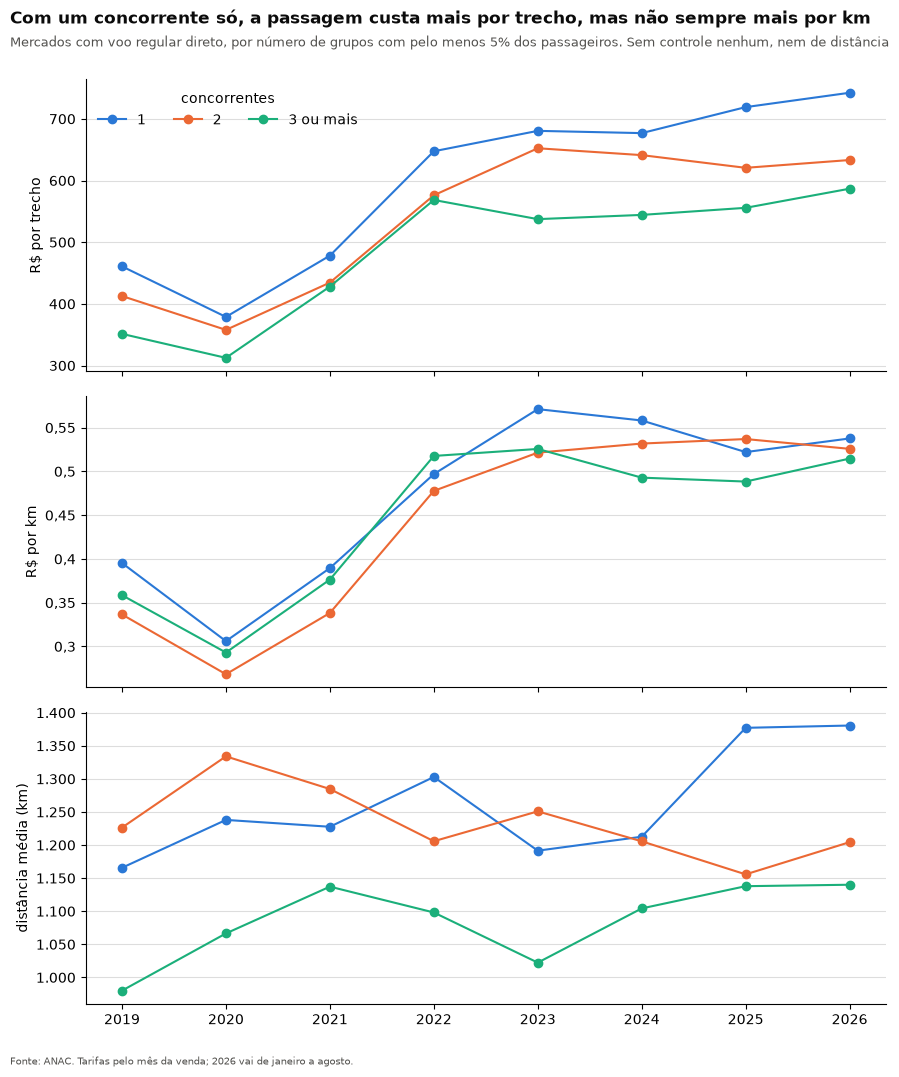

In [5]:
import os
import sys
import urllib.request

if os.path.exists("../visual.py"):
    sys.path.insert(0, "..")
else:  # fora do repositorio (no Colab): o padrao visual vem pela URL bruta
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/visual.py", "visual.py")
from visual import CATEGORICAS, grafico, salvar

fig, eixos = grafico("Com um concorrente só, a passagem custa mais por trecho, mas não sempre mais por km",
                     subtitulo="Mercados com voo regular direto, por número de grupos com pelo menos 5% dos passageiros. "
                               "Sem controle nenhum, nem de distância",
                     fonte="Fonte: ANAC. Tarifas pelo mês da venda; 2026 vai de janeiro a agosto.", linhas=3)
anos = sorted(anual.index.get_level_values("ano").unique())
for ax, medida, rotulo in zip(eixos, ["tarifa_trecho", "tarifa_km", "distancia"],
                              ["R$ por trecho", "R$ por km", "distância média (km)"]):
    for cor, nome in zip(CATEGORICAS, CLASSES):
        serie = anual[medida].xs(nome, level="classe")
        ax.plot(serie.index, serie.values, color=cor, marker="o", label=nome)
    ax.set_ylabel(rotulo)
eixos[0].legend(title="concorrentes", frameon=False, ncols=3, loc="upper left")
eixos[-1].set_xticks(anos)
print("gravado em graficos/" + os.path.basename(salvar(fig, "02-tarifa-por-concorrentes.png")))

## 4. Sensibilidade: o limite e o fretamento

Os 5% são uma escolha. Se trocá-los por 10%, ou contar o fretamento na
participação, mudar a conclusão, isso é achado. A conta abaixo refaz as
classes nos dois casos e repete a tarifa por km:

In [6]:
com_fretamento = mart["passageiros_pagos"] + mart["passageiros_nao_regular"]
com_fretamento = com_fretamento / com_fretamento.groupby([mart["mes"], mart["mercado"]]).transform("sum")
cenarios = {
    "5%, como no mart": classe(contar(mart["participacao"], 0.05)),
    "10%": classe(contar(mart["participacao"], 0.10)),
    "5%, com fretamento": classe(contar(com_fretamento, 0.05)),
}
for nome, classes in cenarios.items():
    mudam = (classes != por_mercado["classe"]).sum()
    registros = com_km.join(classes.rename("cenario"), on=["mes", "mercado"])
    km = por_classe(registros, "cenario")["tarifa_km"].unstack()
    print(f"{nome}: {mudam} mercado-meses mudam de classe; tarifa por km (R$)")
    print(km.round(3).to_string())
    print("  1 acima de 3 ou mais em", (km["1"] > km["3 ou mais"]).sum(), "de", len(km), "anos;",
          "2 entre os dois em", ((km["2"] < km["1"]) & (km["2"] > km["3 ou mais"])).sum(), "\n")

5%, como no mart: 0 mercado-meses mudam de classe; tarifa por km (R$)
cenario      1      2  3 ou mais
ano                             
2019     0.395  0.337      0.359
2020     0.306  0.268      0.293
2021     0.390  0.338      0.376
2022     0.497  0.478      0.518
2023     0.571  0.521      0.526
2024     0.558  0.532      0.493
2025     0.522  0.537      0.488
2026     0.538  0.526      0.515
  1 acima de 3 ou mais em 7 de 8 anos; 2 entre os dois em 2 

10%: 494 mercado-meses mudam de classe; tarifa por km (R$)
cenario      1      2  3 ou mais
ano                             
2019     0.393  0.339      0.358
2020     0.307  0.268      0.294
2021     0.390  0.336      0.380
2022     0.494  0.469      0.524
2023     0.571  0.524      0.524
2024     0.554  0.513      0.499
2025     0.522  0.521      0.493
2026     0.536  0.519      0.518
  1 acima de 3 ou mais em 7 de 8 anos; 2 entre os dois em 3 

5%, com fretamento: 743 mercado-meses mudam de classe; tarifa por km (R$)
cenario      

**Nenhuma das duas muda o quadro.** Com 10%, 494 mercado-meses mudam de
classe; com o fretamento, 743. Nos dois casos, um concorrente segue acima
de três ou mais em 7 dos 8 anos, e os mercados de dois concorrentes seguem
sem lugar fixo: ficam entre os outros dois em 3 anos com 10% e em 2 com o
fretamento.

## 5. O que esta comparação não diz

O preço do quilômetro depende da distância. A conta abaixo divide os
mercado-meses de 2025 em quatro partes iguais, do mais curto ao mais
longo, e calcula as duas tarifas em cada uma:

In [7]:
ano = com_km[(com_km["ano"] == 2025) & (com_km["assentos_vendidos"] > 0)].copy()
ano["distancia_mercado"] = ano["assentos_km"] / ano["assentos_vendidos"]
ano["quartil"], limites = pd.qcut(ano["distancia_mercado"], 4, labels=False, retbins=True)
s = ano.groupby("quartil")[["receita", "assentos_km", "assentos_vendidos"]].sum()
quartis = pd.DataFrame({
    "distância do mercado": [f"de {a:.0f} a {b:.0f} km" for a, b in zip(limites[:-1], limites[1:])],
    "tarifa por km (R$)": (s["receita"] / s["assentos_km"]).round(3),
    "tarifa por trecho (R$)": (s["receita"] / s["assentos_vendidos"]).round(0),
})
print("2025, mercado-meses em quatro partes iguais, do mais curto ao mais longo")
print(quartis.to_string(index=False))
print("tarifa por km sempre caindo:", quartis["tarifa por km (R$)"].is_monotonic_decreasing,
      "| tarifa por trecho sempre subindo:", quartis["tarifa por trecho (R$)"].is_monotonic_increasing)

2025, mercado-meses em quatro partes iguais, do mais curto ao mais longo
distância do mercado  tarifa por km (R$)  tarifa por trecho (R$)
      de 83 a 532 km               1.059                   436.0
     de 532 a 997 km               0.628                   494.0
    de 997 a 1692 km               0.488                   659.0
   de 1692 a 3289 km               0.368                   802.0
tarifa por km sempre caindo: True | tarifa por trecho sempre subindo: True


**Quanto mais longo o mercado, mais barato o quilômetro e mais cara a
passagem.** Em 2025, a tarifa por km cai de R\$ 1,059 nos mercados de 83 a
532 km pra R\$ 0,368 nos de 1.692 a 3.289 km, e a tarifa por trecho sobe de
R\$ 436 pra R\$ 802, sem nenhuma inversão no caminho.

Como os mercados de um concorrente só são mais longos, as duas medidas
erram em sentidos opostos. Por trecho, a distância aumenta a diferença
entre eles e os mercados disputados; por km, diminui. A comparação crua
não separa o efeito da concorrência do da distância e, por isso, não
responde à pergunta. Fica registrada como o "antes":

| 2025 | 1 concorrente | 2 concorrentes | 3 ou mais |
|---|---|---|---|
| Tarifa por trecho | R\$ 719 | R\$ 621 | R\$ 556 |
| Tarifa por km | R\$ 0,522 | R\$ 0,537 | R\$ 0,488 |
| Distância média | 1.377 km | 1.156 km | 1.138 km |

O notebook 03 compara mercados de distância parecida. E, mesmo com a
distância controlada, comparar mercados mostra associação, não efeito:
uma companhia entra num mercado também pelo que espera ganhar nele.